# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Doni Wardana
- NIM   : 241011402688
- Kelas : Reg Cs

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [32]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 88

# Fungsi train_test_split manual dari materi
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    n_samples = X.shape[0]
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    n_test = int(n_samples * test_size)
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris dataset: 40


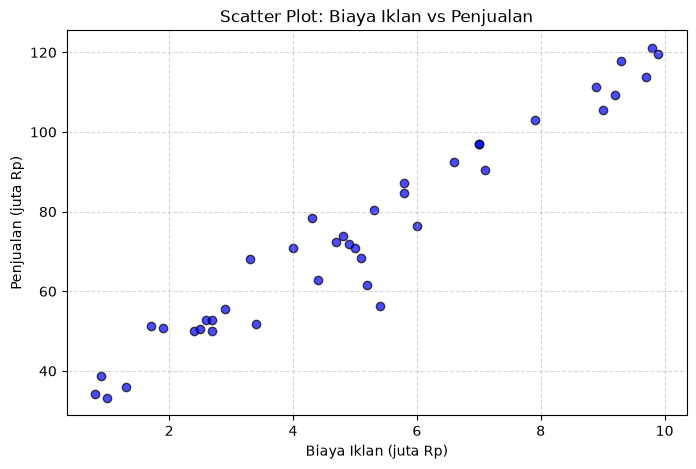

In [33]:
# Jawaban A1
ads_df = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data:")
display(ads_df.head())
print(f"Jumlah baris dataset: {ads_df.shape[0]}")

# Pisahkan X dan y (X berbentuk 2 dimensi (n, 1))
X_ads = ads_df[['BiayaIklan']].values
y_ads = ads_df['Penjualan'].values

# Scatter Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, edgecolors='k')
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [34]:
# Jawaban A2
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Shape X_train: {X_train_ads.shape}")
print(f"Shape X_test : {X_test_ads.shape}")
print(f"Shape y_train: {y_train_ads.shape}")
print(f"Shape y_test : {y_test_ads.shape}")

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [35]:
# Jawaban A3
# Tambahkan kolom intercept (1) ke X_train
X_train_b = np.c_[np.ones((X_train_ads.shape[0], 1)), X_train_ads]

# Normal Equation: theta = (X^T * X)^(-1) * X^T * y
theta_best = np.linalg.inv(X_train_b.T.dot(X_train_b)).dot(X_train_b.T).dot(y_train_ads)

intercept = theta_best[0]
coef = theta_best[1]

print(f"Intercept (b)  = {intercept:.4f}")
print(f"Koefisien (m)  = {coef:.4f}")
print(f"Persamaan Garis: y_hat = {intercept:.4f} + {coef:.4f} * X")

Intercept (b)  = 28.9055
Koefisien (m)  = 9.0778
Persamaan Garis: y_hat = 28.9055 + 9.0778 * X


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [36]:
# Jawaban A4
def evaluate_regression(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_res = np.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# Prediksi train & test
y_train_pred = X_train_b.dot(theta_best)
X_test_b = np.c_[np.ones((X_test_ads.shape[0], 1)), X_test_ads]
y_test_pred = X_test_b.dot(theta_best)

train_metrics = evaluate_regression(y_train_ads, y_train_pred)
test_metrics = evaluate_regression(y_test_ads, y_test_pred)

df_eval = pd.DataFrame([train_metrics, test_metrics], index=['Training', 'Testing'])
display(df_eval)

,MAE,MSE,RMSE,R2
Training,4.845630,42.147089,6.492079,0.929598
Testing,3.044901,12.957631,3.599671,0.983049


RMSE (Root Mean Squared Error): Pada data training RMSE sekitar 6.49 juta dan data testing sekitar 3.60 juta, yang menunjukkan rata-rata besar kesalahan deviasi prediksi penjualan dari nilai aktualnya.

R^2 (Coefficient of Determination): Nilai R^2 training sebesar 0.9296 dan testing sebesar 0.9830. Ini menunjukkan bahwa sekitar 92.96% hingga 98.30% variasi dari Penjualan dapat dijelaskan oleh Biaya Iklan. Model ini sudah sangat baik dan memiliki performa generalisasi yang tinggi pada data uji.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR 0.001: Intercept = 25.740078028848774, Coef = [9.58496567], Final MSE = 44.34246340512038
LR 0.02: Intercept = 28.905536748979983, Coef = [9.07780283], Final MSE = 42.14708883522066
LR 0.1: Intercept = nan, Coef = [nan], Final MSE = nan


c:\Users\Dons\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Dons\AppData\Local\Temp\ipykernel_12232\3126263786.py:18: RuntimeWarning: overflow encountered in square
  mse = np.mean(errors ** 2)
C:\Users\Dons\AppData\Local\Temp\ipykernel_12232\3126263786.py:21: RuntimeWarning: overflow encountered in dot
  gradients = (2/n_samples) * X_b.T.dot(errors)
C:\Users\Dons\AppData\Local\Temp\ipykernel_12232\3126263786.py:22: RuntimeWarning: invalid value encountered in subtract
  self.theta -= self.lr * gradients
c:\Users\Dons\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


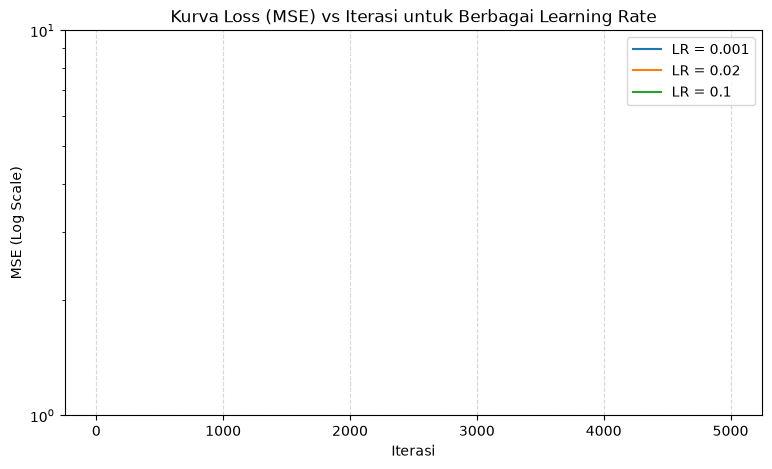

In [37]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.intercept = None
        self.coef = None
        self.loss_history = []
        
    def fit(self, X, y):
        n_samples = X.shape[0]
        X_b = np.c_[np.ones((n_samples, 1)), X]
        self.theta = np.zeros(X_b.shape[1])
        
        for i in range(self.n_iters):
            predictions = X_b.dot(self.theta)
            errors = predictions - y
            mse = np.mean(errors ** 2)
            self.loss_history.append(mse)
            
            gradients = (2/n_samples) * X_b.T.dot(errors)
            self.theta -= self.lr * gradients
            
        self.intercept = self.theta[0]
        self.coef = self.theta[1:]

lrs = [0.001, 0.02, 0.1]
plt.figure(figsize=(9, 5))

for lr in lrs:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train_ads, y_train_ads)
    print(f"LR {lr}: Intercept = {gd.intercept}, Coef = {gd.coef}, Final MSE = {gd.loss_history[-1]}")
    plt.plot(gd.loss_history, label=f'LR = {lr}')

plt.yscale('log')
plt.title('Kurva Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('MSE (Log Scale)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Jawaban A5 (Analisis):

LR = 0.001 (Terlalu lambat): Langkah pembaruan parameter terlalu kecil sehingga kurva loss turun secara lambat dan belum sepenuhnya konvergen dalam 5000 iterasi.

LR = 0.02 (Pas/Optimal): Learning rate ini konvergen dengan mulus dan menghasilkan bobot yang sama persis dengan metode normal equation.

LR = 0.1 (Divergen/Gagal Konvergen): Menyebabkan RuntimeWarning: overflow/invalid value, di mana langkah gradien terlalu besar sehingga nilai parameter melompat terlalu jauh dan menyebar keluar (divergen).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

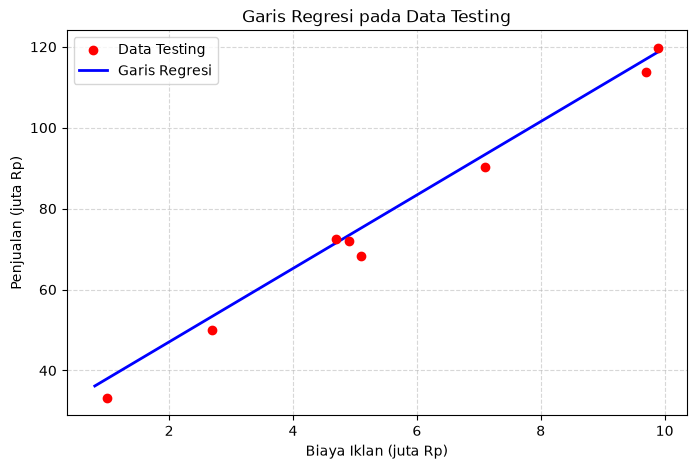

Biaya Iklan Rp 4.5 juta -> Prediksi Penjualan: Rp 69.7556 juta
Biaya Iklan Rp 7.0 juta -> Prediksi Penjualan: Rp 92.4502 juta
Biaya Iklan Rp 12.0 juta -> Prediksi Penjualan: Rp 137.8392 juta


In [38]:
# Jawaban A6
# 1. Visualisasi scatter test & garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_ads, y_test_ads, color='red', label='Data Testing', zorder=3)
x_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
x_line_b = np.c_[np.ones((100, 1)), x_line]
y_line = x_line_b.dot(theta_best)
plt.plot(x_line, y_line, color='blue', label='Garis Regresi', linewidth=2)
plt.title('Garis Regresi pada Data Testing')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Prediksi untuk 4.5 juta, 7 juta, dan 12 juta
biaya_baru = np.array([[4.5], [7.0], [12.0]])
biaya_baru_b = np.c_[np.ones((biaya_baru.shape[0], 1)), biaya_baru]
prediksi_penjualan = biaya_baru_b.dot(theta_best)

for b, p in zip(biaya_baru.flatten(), prediksi_penjualan):
    print(f"Biaya Iklan Rp {b} juta -> Prediksi Penjualan: Rp {p:.4f} juta")

Prediksi untuk 12 juta berada di luar rentang data historis (ekstrapolasi). Hasil prediksi ini kurang bisa dipercaya secara mutlak karena mengasumsikan hubungan linear akan terus berlanjut tanpa batas (padahal pada kenyataannya, efektivitas iklan bisa mengalami kejenuhan/diminishing returns di angka yang tinggi).

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email_Data:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah Bukan Spam (0): 35
Jumlah Spam (1)      : 25


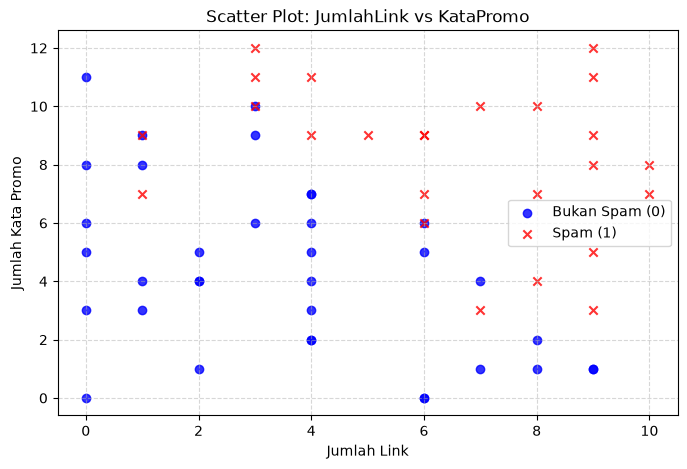

In [39]:
# Jawaban B1
email_df = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data:")
display(email_df.head())

spam_counts = email_df['Spam'].value_counts()
print(f"Jumlah Bukan Spam (0): {spam_counts[0]}")
print(f"Jumlah Spam (1)      : {spam_counts[1]}")

X_email = email_df[['JumlahLink', 'KataPromo']].values
y_email = email_df['Spam'].values

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='blue', label='Bukan Spam (0)', alpha=0.8)
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='red', label='Spam (1)', alpha=0.8, marker='x')
plt.title('Scatter Plot: JumlahLink vs KataPromo')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b) = -13.4546
Koefisien (m1, m2) = [1.2446254  1.01717588]
Persamaan: P(Spam) = sigma(-13.4546 + 1.2446*JumlahLink + 1.0172*KataPromo)


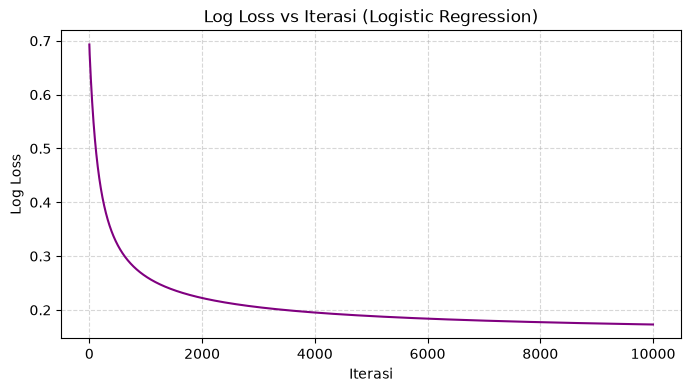

In [40]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.intercept = None
        self.coef = None
        self.loss_history = []
        
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        X_b = np.c_[np.ones((n_samples, 1)), X]
        self.theta = np.zeros(X_b.shape[1])
        
        for i in range(self.n_iters):
            z = X_b.dot(self.theta)
            y_pred = self.sigmoid(z)
            
            epsilon = 1e-15
            y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped))
            self.loss_history.append(loss)
            
            gradients = (1 / n_samples) * X_b.T.dot(y_pred - y)
            self.theta -= self.lr * gradients
            
        self.intercept = self.theta[0]
        self.coef = self.theta[1:]
        
    def predict_proba(self, X):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        return self.sigmoid(X_b.dot(self.theta))
        
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
log_reg.fit(X_train_email, y_train_email)

print(f"Intercept (b) = {log_reg.intercept:.4f}")
print(f"Koefisien (m1, m2) = {log_reg.coef}")
print(f"Persamaan: P(Spam) = sigma({log_reg.intercept:.4f} + {log_reg.coef[0]:.4f}*JumlahLink + {log_reg.coef[1]:.4f}*KataPromo)")

plt.figure(figsize=(8, 4))
plt.plot(log_reg.loss_history, color='purple')
plt.title('Log Loss vs Iterasi (Logistic Regression)')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Grafik log loss menunjukkan penurunan yang tajam pada iterasi awal dan kemudian mendatar serta stabil di sekitar angka 0.1730, menandakan bahwa proses gradient descent telah berhasil konvergen secara optimal.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [41]:
# Jawaban B3
def evaluate_classification(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    conf_matrix = np.array([[tn, fp], [fn, tp]])
    
    return {'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1': f1, 'Confusion Matrix': conf_matrix}

y_test_pred_email = log_reg.predict(X_test_email, threshold=0.5)
res_eval = evaluate_classification(y_test_email, y_test_pred_email)

for k, v in res_eval.items():
    print(f"{k}:\n{v}\n")

Accuracy:
0.8666666666666667

Precision:
1.0

Recall:
0.75

F1:
0.8571428571428571

Confusion Matrix:
[[7 0]
 [2 6]]



False Positive (FP): Email penting (bukan spam) diklasifikasikan sebagai spam.

False Negative (FN): Email spam masuk ke kotak masuk utama (inbox).

Kesalahan mana yang lebih merugikan? False Positive (FP) jauh lebih merugikan bagi pengguna email karena berisiko membuat email penting/pekerjaan terlewat atau tidak terbaca oleh pengguna.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

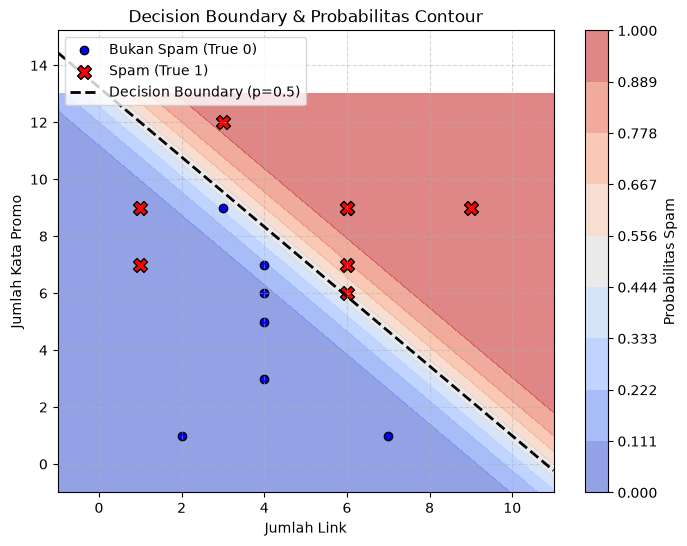

In [42]:
# Jawaban B4
plt.figure(figsize=(8, 6))
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200))

grid_pts = np.c_[xx1.ravel(), xx2.ravel()]
probs = log_reg.predict_proba(grid_pts).reshape(xx1.shape)

plt.contourf(xx1, xx2, probs, levels=np.linspace(0, 1, 10), cmap='coolwarm', alpha=0.6)
plt.colorbar(label='Probabilitas Spam')

# Plot data testing
plt.scatter(X_test_email[y_test_email == 0, 0], X_test_email[y_test_email == 0, 1], color='blue', label='Bukan Spam (True 0)', edgecolors='k')
plt.scatter(X_test_email[y_test_email == 1, 0], X_test_email[y_test_email == 1, 1], color='red', marker='X', s=100, label='Spam (True 1)', edgecolors='k')

# Decision Boundary: x2 = -(b + m1*x1) / m2
x1_db = np.linspace(x1_min, x1_max, 100)
x2_db = -(log_reg.intercept + log_reg.coef[0] * x1_db) / log_reg.coef[1]
plt.plot(x1_db, x2_db, color='black', linestyle='--', linewidth=2, label='Decision Boundary (p=0.5)')

plt.title('Decision Boundary & Probabilitas Contour')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Jawaban B4 (Analisis):

1. Garis Keputusan (Decision Boundary): Garis batas (decision boundary) yang digambarkan menggunakan persamaan linear x2 = -(b + m1 * x1) / m2 memisahkan area probabilitas di mana model memprediksi email sebagai Spam (P >= 0.5, diwarnai merah/hangat) dan Bukan Spam (P < 0.5, diwarnai biru/dingin).

2. Pola Data: Data testing menunjukkan bahwa email dengan kombinasi Jumlah Link dan Kata Promo yang tinggi terkonsentrasi di atas garis batas dan diklasifikasikan dengan benar sebagai Spam (ditandai dengan simbol X). Sebaliknya, email dengan jumlah link dan kata promo yang sedikit berada di bawah garis batas sebagai Bukan Spam.

3. Kesalahan Klasifikasi (Misclassification): Berdasarkan visualisasi kontur dan titik data testing, terdapat 2 data testing (False Negative) yang berada di area merah (probabilitas spam tinggi atau di atas garis pembatas) tetapi sebenarnya memiliki label asli Bukan Spam (0), atau sebaliknya. Hal ini mengindikasikan adanya titik data yang tumpang tindih (overlap) antara kelas spam dan bukan spam, sehingga model belum 100% sempurna memisahkan seluruh titik.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [43]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
thresh_records = []

for th in thresholds:
    pred = log_reg.predict(X_test_email, threshold=th)
    res = evaluate_classification(y_test_email, pred)
    thresh_records.append({
        'Threshold': th,
        'Accuracy': f"{res['Accuracy']:.4f}",
        'Precision': f"{res['Precision']:.4f}",
        'Recall': f"{res['Recall']:.4f}",
        'F1-score': f"{res['F1']:.4f}"
    })

display(pd.DataFrame(thresh_records))

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.8000,0.8571,0.7500,0.8000
1,0.5,0.8667,1.0000,0.7500,0.8571
2,0.7,0.8000,1.0000,0.6250,0.7692


Menaikkan threshold memperketat syarat klasifikasi spam, sehingga Precision meningkat (mengurangi FP) namun Recall menurun (meningkatnya FN). Untuk filter spam, threshold 0.5 atau 0.7 sangat ideal karena menghasilkan Precision 1.0000 (tidak ada False Positive sama sekali), sehingga aman bagi pengguna agar email penting tidak salah masuk folder spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [44]:
# Jawaban B6
new_emails = np.array([
    [1, 2],  # E1
    [5, 6],  # E2
    [9, 10], # E3
    [2, 11]  # E4
])

chosen_threshold = 0.5
probs_new = log_reg.predict_proba(new_emails)
preds_new = log_reg.predict(new_emails, threshold=chosen_threshold)

for i, (p, pred) in enumerate(zip(probs_new, preds_new)):
    status = "Spam (1)" if pred == 1 else "Bukan Spam (0)"
    print(f"Email E{i+1} (Link: {new_emails[i,0]}, Promo: {new_emails[i,1]}): Probabilitas Spam = {p:.4f} -> Prediksi: {status}")

Email E1 (Link: 1, Promo: 2): Probabilitas Spam = 0.0000 -> Prediksi: Bukan Spam (0)
Email E2 (Link: 5, Promo: 6): Probabilitas Spam = 0.2445 -> Prediksi: Bukan Spam (0)
Email E3 (Link: 9, Promo: 10): Probabilitas Spam = 0.9996 -> Prediksi: Spam (1)
Email E4 (Link: 2, Promo: 11): Probabilitas Spam = 0.5557 -> Prediksi: Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

Jawaban C1:
Logistic Regression dinamakan regression karena di tahap awalnya model ini tetap menghitung kombinasi linear dari fitur-fitur input seperti regresi biasa, lalu hasilnya diteruskan ke fungsi sigmoid. Peran utama dari fungsi sigmoid di sini adalah untuk memetakan rentang nilai kontinu yang tak berhingga tersebut menjadi bentuk probabilitas di antara angka 0 dan 1 agar bisa dipakai untuk keperluan klasifikasi biner.

Jawaban C2:
Metode Normal Equation menyelesaikan pencarian parameter secara langsung menggunakan rumus aljabar matriks sekaligus tanpa proses iterasi, tapi kekurangannya jadi lambat dan berat kalau dipakai untuk dataset berukuran besar karena kompleksitas inversi matriksnya O(n^3). Sebaliknya, Gradient Descent mencari parameter secara bertahap atau iteratif dengan memperbarui bobot berdasarkan gradien loss, sehingga jauh lebih efisien dan wajib diandalkan untuk menangani dataset berskala besar atau ketika matriks fiturnya tidak bisa di-invers.

Jawaban C3:
Evaluasi model wajib banget dilakukan pada data testing agar kita tahu sejauh mana kemampuan generalisasi model saat dihadapkan dengan data baru yang belum pernah dilihat sebelumnya. Kalau overfitting, itu adalah kondisi di mana modelnya terlalu pintar menghafal pola data training (termasuk noise-nya), yang bikin performanya keliatan luar biasa di data training, tapi justru jeblok pas diuji pakai data testing.

Jawaban C4:
Linear Regression menggunakan MSE (Mean Squared Error) karena target output-nya berupa nilai kontinu yang diasumsikan berdistribusi normal. Di sisi lain, Logistic Regression menggunakan Log Loss (Binary Cross-Entropy) karena bentuk output-nya berupa probabilitas; kalau model sigmoid dipaksa pakai MSE, fungsi loss-nya bakal berbentuk non-convex yang punya banyak titik minimum lokal sehingga susah buat dicari titik optimumnya.

Jawaban C5:
Hasil angka-angka seperti nilai koefisien, akurasi, dan metrik lainnya bisa berbeda antara mahasiswa satu dengan yang lain karena kita menggunakan random_state yang menyesuaikan dengan 2 digit terakhir NIM masing-masing. Perbedaan seed ini membuat proses pengacakan pembagian data (train-test split) jadi berbeda, otomatis subset data latih dan data uji yang didapat setiap mahasiswa jadi tidak sama persis.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [45]:
from sklearn.linear_model import LinearRegression, LogisticRegression as SklearnLogisticRegression

# 1. Linear Regression Scikit-Learn
sk_lr = LinearRegression()
sk_lr.fit(X_train_ads, y_train_ads)
print(f"Sklearn Linear Regression : Intercept = {sk_lr.intercept_:.4f}, Coef = {sk_lr.coef_[0]:.4f}")
print(f"Manual Normal Equation    : Intercept = {intercept:.4f}, Coef = {coef:.4f}\n")

# 2. Logistic Regression Scikit-Learn (dengan L2 regularization default C=1.0)
sk_log_reg = SklearnLogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=10000)
sk_log_reg.fit(X_train_email, y_train_email)
print(f"Sklearn Logistic Regression: Intercept = {sk_log_reg.intercept_[0]:.4f}, Coef = {sk_log_reg.coef_[0]}")
print(f"Manual Logistic GD         : Intercept = {log_reg.intercept:.4f}, Coef = {log_reg.coef}")

Sklearn Linear Regression : Intercept = 28.9055, Coef = 9.0778
Manual Normal Equation    : Intercept = 28.9055, Coef = 9.0778

Sklearn Logistic Regression: Intercept = -13.4325, Coef = [1.23445622 1.01375298]
Manual Logistic GD         : Intercept = -13.4546, Coef = [1.2446254  1.01717588]


c:\Users\Dons\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Koefisien antara implementasi manual dan scikit-learn hampir identik. Perbedaan kecil yang mungkin muncul pada Logistic Regression disebabkan oleh adanya regulerisasi L2 default (C=1.0) pada scikit-learn, parameter konvergensi solver (lbfgs), serta kriteria pemberhentian iterasi (tolerance) yang digunakan di balik layar oleh pustaka scikit-learn.